# Background aerosol, sources and chemistry: LCC − CTRL in the PD and FUT backgrounds

**Question.** Does the forest expansion change the aerosol and chemistry background, through which online sources, and **does the answer depend on the background climate** (PD or FUT)?

**Runs (new chain), 2001–2025** (first 12 months dropped as spin-up). All are nudged to the same PD winds, so year *y* of one run is paired with year *y* of the others.

| | CTRL | LCC |
|---|---|---|
| **PD** | CTRL_PD `NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029` | LCC_PD `NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028` |
| **FUT** | CTRL_FUT `NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028` | LCC_FUT `NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028` |

**Three contrasts**, each computed year by year:
- **ΔPD** = LCC_PD − CTRL_PD: forest-expansion effect in the PD background.
- **ΔFUT** = LCC_FUT − CTRL_FUT: forest-expansion effect in the FUT background.
- **ΔFUT − ΔPD**: how much the background climate changes the forest-expansion effect (the interaction).

**This notebook integrates** `background_aerosol_pd_fut_online.ipynb` (regions, online-source totals, bars, time series, Arctic and global maps) and `background_aerosol_lcc_ctrl_fut_online.ipynb` (namelist diff, modified cells, SOA/BVOC/OH variables, paired statistics, hatching). Prescribed inputs: `background_aerosol_pd_fut_prescribed.ipynb`.

**Statistics.** Paired t-test of the 25 yearly differences (`analysis/stats.py` method, copied here). Maps: Benjamini–Hochberg FDR (α = 0.10) over the plotted domain; **hatching = not significant**. Yearly values are treated as independent, so p-values may be too small if differences are autocorrelated.

**Regions.** global, NH, SH, **46–82°N** (the only latitudes where the land cover differs), **modified cells** (land cells whose PFTs changed, `diagnostics/lcc-modified-cells/modified_cells.nc`), Arctic >66.5°N. Maps: Arctic (north of 45°N, dashed = 66.5°N, black line = modified cells); global versions in the Appendix.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
import re, difflib, warnings
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.path as mpath
import cartopy.crs as ccrs
from scipy import stats as sps

CASEDIR = Path.home() / 'cases/BRL_FRST_XPSN'
CASES = {'CTRL_PD': 'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029',
         'LCC_PD': 'NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028',
         'CTRL_FUT': 'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028',
         'LCC_FUT': 'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028'}
PAIRS = {'PD': ('CTRL_PD', 'LCC_PD'), 'FUT': ('CTRL_FUT', 'LCC_FUT')}
PROC = Path('../../data/processed-data/postprocessing')
PROC_YEARS = '2001-2025'
YEARS = list(range(2001, 2026))
YRS = f'{YEARS[0]}–{YEARS[-1]}'
DMS_DIR = Path('/cluster/shared/noresm/inputdata/noresm-only/atm/cam/camoslo')
MOD_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('background_aerosol_lcc_ctrl_pd_fut_online_outputs')
CACHE, FIG, TAB = OUT / 'cache', OUT / 'figures', OUT / 'tables'  # cache = symlink to /cluster/work
FIG_GLOBAL = FIG / 'appendix-global'
for d in (CACHE, FIG, TAB, FIG_GLOBAL):
    d.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
N_WORKERS = 8
R_EARTH = 6.371e6
DPM = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])  # noleap
LAT_MAP = 45   # Arctic maps: north of this latitude
LAT_BOX = 40   # regional totals (bars, time series): north of this latitude
ALPHA_FDR = 0.10
APPENDIX = []  # map calls, replayed globally in the Appendix
# project palette, in order; gold = total; PD = navy, FUT = red
TEAL, NAVY, PLUM, RED, ORANGE, GOLD, GREY = '#5D9A92', '#2C3990', '#9A4A84', '#BC423E', '#DE7A3A', '#EBC45C', '#CCCCCC'
PCOL = {'PD': NAVY, 'FUT': RED}

def cell_area(lat, nlon):
    lat = np.asarray(lat, float)
    edges = np.clip(np.concatenate([[-90], 0.5 * (lat[1:] + lat[:-1]), [90]]), -90, 90)
    band = R_EARTH**2 * np.deg2rad(360 / nlon) * np.diff(np.sin(np.deg2rad(edges)))
    return np.repeat(band[:, None], nlon, axis=1)  # m2

with xr.open_dataset(PROC / f'CTRL_FUT_atm_METEO_{PROC_YEARS}.nc') as g:
    AREA = xr.DataArray(cell_area(g.lat, g.lon.size), dims=('lat', 'lon'), coords=dict(lat=g.lat.values, lon=g.lon.values))
assert abs(AREA.sum() / (4 * np.pi * R_EARTH**2) - 1) < 1e-6
with xr.open_dataset(MOD_FILE) as m:
    assert np.allclose(m.lat, AREA.lat) and np.allclose(m.lon, AREA.lon)
    MOD = (m.modified.astype(bool)).assign_coords(lat=AREA.lat, lon=AREA.lon).load()
LAT = AREA.lat.broadcast_like(AREA)
REGIONS = {'global': AREA, 'NH': AREA * (LAT > 0), 'SH': AREA * (LAT < 0), '46–82°N': AREA * ((LAT >= 46) & (LAT <= 82)),
           'modified cells': AREA * MOD, 'Arctic >66.5°N': AREA * (LAT > 66.5)}
print('modified cells:', int(MOD.sum()), f'({float((AREA * MOD).sum()) / 1e12:.2f} million km²), lat',
      float(LAT.where(MOD).min()), '–', float(LAT.where(MOD).max()))

# --- statistics (as src/boreal_forest_expansion/analysis/stats.py) ---
def pvalue(d, dim='year'):
    """Two-sided one-sample t-test of the paired yearly differences."""
    def _p(x):
        with warnings.catch_warnings(), np.errstate(invalid='ignore', divide='ignore'):
            warnings.simplefilter('ignore', RuntimeWarning)
            return sps.ttest_1samp(x, 0.0, axis=-1, nan_policy='omit').pvalue
    return xr.apply_ufunc(_p, d, input_core_dims=[[dim]])

def fdr_mask(p, within, alpha=ALPHA_FDR):
    """Benjamini-Hochberg over the cells in `within`."""
    pv = p.values.copy()
    valid = np.isfinite(pv) & within.values.astype(bool)
    sig = np.zeros_like(pv, dtype=bool)
    flat = pv[valid]
    if flat.size:
        ranked = np.sort(flat)
        below = np.nonzero(ranked <= alpha * np.arange(1, flat.size + 1) / flat.size)[0]
        if below.size:
            sig[valid] = flat <= ranked[below.max()]
    return xr.DataArray(sig, coords=p.coords, dims=p.dims)

def mean_ci_p(d):
    d = np.asarray(d, float)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        p = sps.ttest_1samp(d, 0.0).pvalue
    return d.mean(), sps.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d)), p

def contrast_row(y):
    """y = {run: yearly values}. Levels, ΔPD, ΔFUT (with % of CTRL, 95 % CI, p) and ΔFUT − ΔPD."""
    row = {r: y[r].mean() for r in CASES}
    dd = {b: y[l] - y[c] for b, (c, l) in PAIRS.items()}
    for b, (c, _) in PAIRS.items():
        m, ci, p = mean_ci_p(dd[b])
        row.update({f'Δ{b}': m, f'Δ{b} %': 100 * m / y[c].mean() if y[c].mean() else np.nan, f'Δ{b} CI': ci, f'Δ{b} p': p})
    m, ci, p = mean_ci_p(dd['FUT'] - dd['PD'])
    row.update({'ΔFUT − ΔPD': m, 'ΔFUT − ΔPD CI': ci, 'ΔFUT − ΔPD p': p})
    return row

def region_table(fields, fname):
    """fields: {name: (unit, {run: yearly da}, factor to the table unit, 'mean'|'sum')}."""
    rows = []
    for name, (unit, das, fac, how) in fields.items():
        for r, w in REGIONS.items():
            agg = (lambda x: (x * w).sum(('lat', 'lon'))) if how == 'sum' else (lambda x: (x * w).sum(('lat', 'lon')) / w.sum())
            rows.append(dict(variable=name, unit=unit, region=r, **contrast_row({k: agg(v).values * fac for k, v in das.items()})))
    tab = pd.DataFrame(rows).set_index(['variable', 'unit', 'region'])
    tab.to_csv(TAB / fname)
    return tab

SHOW = ['CTRL_PD', 'ΔPD', 'ΔPD %', 'ΔPD p', 'CTRL_FUT', 'ΔFUT', 'ΔFUT %', 'ΔFUT p', 'ΔFUT − ΔPD', 'ΔFUT − ΔPD p']
def show(tab, regions=('global', 'modified cells', '46–82°N', 'Arctic >66.5°N')):
    with pd.option_context('display.float_format', '{:.3g}'.format, 'display.max_rows', 200, 'display.width', 250):
        for r in regions:
            print(r); display(tab.xs(r, level='region')[SHOW])

# --- maps: ΔPD, ΔFUT, ΔFUT − ΔPD; hatching = not significant (as forcing_maps.add_stippling style='lines') ---
def cyclic(da):
    return xr.concat([da, da.isel(lon=0).assign_coords(lon=360.)], 'lon')

def setup_map(ax, region):
    if region == 'arctic':
        ax.set_extent([-180, 180, LAT_MAP, 90], ccrs.PlateCarree())
        th = np.linspace(0, 2 * np.pi, 200)
        ax.set_boundary(mpath.Path(np.c_[np.sin(th), np.cos(th)] * 0.5 + 0.5), transform=ax.transAxes)
        ax.plot(np.linspace(0, 360, 361), np.full(361, 66.5), ls='--', lw=0.6, color='k', transform=ccrs.PlateCarree())
    else:
        ax.set_global()
    ax.coastlines(lw=0.4)

def hatch(ax, mask):
    da = cyclic(mask.astype(float))
    cs = ax.contourf(da.lon, da.lat, np.where(da > 0.5, 1.0, np.nan), levels=[0.5, 1.5], colors='none',
                     hatches=['/////'], transform=ccrs.PlateCarree(), zorder=4)
    cs.set_edgecolor('dimgrey'); cs.set_linewidth(0.0); cs.set_hatch_linewidth(0.3)

def outline_modified(ax):
    da = cyclic(MOD.astype(float))
    ax.contour(da.lon, da.lat, da, levels=[0.5], colors='k', linewidths=0.5, transform=ccrs.PlateCarree(), zorder=5)

def white_zero(cmap, levels, extend='both'):
    """Same colours per bin as BoundaryNorm(levels, cmap.N, extend), except the bin that contains 0 is pure white."""
    cm = plt.get_cmap(cmap)
    levels = np.asarray(levels, float)
    off, n_ext = {'neither': (0, 0), 'min': (1, 1), 'max': (0, 1), 'both': (1, 2)}[extend]
    nreg = len(levels) - 1 + n_ext
    cols = cm(((cm.N - 1) / (nreg - 1) * np.arange(nreg)).astype(int))
    for i in range(len(levels) - 1):
        if levels[i] < 0 < levels[i + 1]:
            cols[i + off] = (1, 1, 1, 1)
    return mcolors.ListedColormap(cols), mcolors.BoundaryNorm(levels, nreg, extend=extend)

def sym_levels(vmax, n=6):
    """±(1..n) × a 1-2-2.5-5 step; the central bin (−step, step) is white."""
    step = vmax / n
    e = 10 ** np.floor(np.log10(step))
    step = min(m * e for m in (1, 2, 2.5, 5, 10) if m * e >= step * 0.999)
    k = np.arange(1, n + 1) * step
    return np.r_[-k[::-1], k]

def contrast_maps(rows, fname, suptitle, region='arctic'):
    """rows: list of (name, unit, {run: yearly da}, domain). One row per variable, one colour scale per row."""
    if region == 'arctic':
        APPENDIX.append((contrast_maps, (rows, fname, suptitle), {}))
    proj = ccrs.NorthPolarStereo() if region == 'arctic' else ccrs.Robinson()
    size = (12.5, 4.0 * len(rows)) if region == 'arctic' else (16, 2.9 * len(rows))
    fig, axs = plt.subplots(len(rows), 3, figsize=size, subplot_kw=dict(projection=proj), layout='constrained', squeeze=False)
    w = REGIONS['modified cells']
    for row, (name, unit, das, dom) in zip(axs, rows):
        dP, dF = (das[PAIRS[b][1]] - das[PAIRS[b][0]] for b in ('PD', 'FUT'))
        within = dom & (LAT >= LAT_MAP) if region == 'arctic' else dom
        pooled = np.abs(np.r_[dP.mean('year').where(within).values.ravel(), dF.mean('year').where(within).values.ravel()])
        vmax = float(np.nanpercentile(pooled, 99)) or 1e-30
        lv = sym_levels(vmax)
        cmap, norm = white_zero('RdBu_r', lv)
        for ax, (lab, d) in zip(row, [('ΔPD', dP), ('ΔFUT', dF), ('ΔFUT − ΔPD', dF - dP)]):
            setup_map(ax, region)
            dm = d.mean('year')
            sig = fdr_mask(pvalue(d), within)
            cd = cyclic(dm.where(dom))
            im = ax.pcolormesh(cd.lon, cd.lat, cd, cmap=cmap, norm=norm, transform=ccrs.PlateCarree(), shading='nearest')
            hatch(ax, within & ~sig)
            outline_modified(ax)
            ax.set_title(f'{name}: {lab}\nmodified cells {float((dm * w).sum() / w.sum()):+.3g} {unit}', fontsize=9)
        cb = fig.colorbar(im, ax=row, orientation='vertical', shrink=0.85, ticks=lv, format=lambda x, _: f'{x:g}')
        cb.set_label(unit, fontsize=8); cb.ax.tick_params(labelsize=7)
    where = f'Arctic, north of {LAT_MAP}°N (dashed = 66.5°N)' if region == 'arctic' else 'global'
    fig.suptitle(f'{suptitle}: LCC − CTRL, {YRS}, {where}\nhatched = not significant (paired t-test, FDR {ALPHA_FDR}); black line = modified cells', fontsize=11)
    fig.savefig((FIG if region == 'arctic' else FIG_GLOBAL) / fname, dpi=170, bbox_inches='tight')
    plt.show()

modified cells: 1161 (29.13 million km²), lat 46.42105263157893 – 82.42105263157893


## 1. Inputs: what differs between the runs

Resolved namelists (`CaseDocs/`) of LCC vs CTRL in each background, with the case names replaced by `<CASE>`. Log-file names are ignored; every other line that differs is printed. The checks below confirm that **both backgrounds use the same pair of land-cover files**, so one modified-cell mask applies to both.

In [2]:
def norm_lines(case, fname):
    txt = (CASEDIR / case / 'CaseDocs' / fname).read_text()
    return [l.rstrip() for l in txt.replace(case, '<CASE>').splitlines() if 'logfile' not in l]

for b, (c, l) in PAIRS.items():
    files = sorted({f.name for k in (c, l) for f in (CASEDIR / CASES[k] / 'CaseDocs').iterdir() if f.is_file()})
    changed = []
    print(f'\n########## {l} vs {c}')
    for fname in files:
        dl = [x[:150] for x in difflib.unified_diff(norm_lines(CASES[c], fname), norm_lines(CASES[l], fname), c, l, n=0, lineterm='')
              if x[:1] in '+-' and x[:3] not in ('+++', '---')]
        if dl:
            changed.append(fname); print(f'=== {fname}'); print('\n'.join(dl))
    print('files compared:', len(files), '| with differences:', changed)

def nml_value(case, key, fname):
    return re.search(rf"\b{key}\s*=\s*(.*?)\n\s*(?:\w+\s*=|/)", (CASEDIR / case / 'CaseDocs' / fname).read_text(), re.S).group(1).strip().strip("'\"")
def env_value(case, key):
    for f in sorted((CASEDIR / case).glob('env_*.xml')):
        m = re.search(rf'id="{key}" value="([^"]*)"', f.read_text())
        if m:
            return m.group(1)
    raise KeyError(key)

FSURDAT = {k: nml_value(c, 'fsurdat', 'lnd_in') for k, c in CASES.items()}
for k, v in FSURDAT.items():
    print(f'{k:9s} fsurdat: {Path(v).name}')
assert FSURDAT['LCC_PD'] == FSURDAT['LCC_FUT'] and FSURDAT['CTRL_PD'] == FSURDAT['CTRL_FUT'] and FSURDAT['LCC_PD'] != FSURDAT['CTRL_PD']
for b, (c, l) in PAIRS.items():
    assert env_value(CASES[c], 'SSTICE_DATA_FILENAME') == env_value(CASES[l], 'SSTICE_DATA_FILENAME'), b
    for key, fn in (('flbc_file', 'atm_in'), ('ocean_filename', 'atm_in'), ('srf_emis_specifier', 'atm_in'), ('ext_frc_specifier', 'atm_in')):
        assert nml_value(CASES[c], key, fn) == nml_value(CASES[l], key, fn), (b, key)
print('OK: within each background, CTRL and LCC share SST/sea ice, GHG, seawater DMS and all prescribed emissions.')


########## LCC_PD vs CTRL_PD
=== atm_in
- ncdata		= 'NF2000norbc_tropstratchem_spinup_ctrl_f19_f19-20261026.cam.i.0021-01-01-00000.nc'
+ ncdata		= 'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20261025.cam.i.0021-01-01-00000.nc'
=== ice_in
-  ice_ic = "NF2000norbc_tropstratchem_spinup_ctrl_f19_f19-20261026.cice.r.0021-01-01-00000.nc"
+  ice_ic = "NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20261025.cice.r.0021-01-01-00000.nc"
=== lnd_in
- finidat = 'NF2000norbc_tropstratchem_spinup_ctrl_f19_f19-20261026.clm2.r.0021-01-01-00000.nc'
+ finidat = 'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20261025.clm2.r.0021-01-01-00000.nc'
- fsurdat = '/cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/release-clm5.0.18/surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c190304.nc'
+ fsurdat = '/cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc'
=== mosart_in
-  finidat_rtm = "NF2000norbc_tropstratchem_spinup_ctrl_f19_f19-20261026.mosart.r.0021-01-

## 2. Online sources: MEGAN BVOC, dust, sea salt, ocean DMS flux, lightning NOx

How each source is computed (same code as the two source notebooks):

| Source | What drives it | How it is computed here | Evidence |
|---|---|---|---|
| **MEGAN BVOC** (19 CAM species) | CLM vegetation, leaf area, temperature, light, soil moisture, CO₂ | CLM `MEG_<compound>` × `landfrac`, summed with `megan_specifier` | (a) model output, checked vs CAM `MEG_ISOP`, `MEG_MTERP` |
| **Dust** | CLM wind, soil moisture, snow, vegetation | raw CLM `DSTFLXT` × `landfrac` × erodibility / `dust_emis_fact` × 1.15 | formula (a); absolute value (b): no CAM dust-emission output |
| **Sea salt** (3 modes, number) | 10-m wind, open ocean, SST | Salter et al. (2015) on **monthly means** | (b): underestimates the absolute flux; contrasts are more robust |
| **Ocean DMS flux** | seawater DMS, wind, SST, open ocean | `oslo_aero_dms_emis` formula on monthly means | (b), same caveat |
| **Lightning NOx** | convective cloud-top height | global value CAM prints each time step in `atm.log` | (a); global only, no map |

Within a background, SST, sea ice and seawater DMS are identical in CTRL and LCC, so ΔPD and ΔFUT of sea salt and DMS flux can come **only from the 10-m wind**.

In [3]:
import gzip
ARCHIVES = [Path('/cluster/work/users/adelez/archive'), Path.home() / 'BRL-FRST-XPSN_archive']  # live archive first (has 2015–2025)
SEC_YR = 365 * 86400
MW_DMS, MW_S = 62.13, 32.06
# Salter et al. (2015) sea-salt number flux, 3 modes: coefficients of SST³, SST², SST, 1 (oslo_aero_seasalt.F90)
SS_COEF = np.array([[-5.2168e5, 3.31725e7, -6.95275e8, 1.0684e10],
                    [0.0,       7.374e5,  -2.4803e7,   7.7373e8],
                    [0.0,       1.4210e4,  1.4662e7,   1.7075e8]])

def read_nml(case, key, fname='atm_in'):
    txt = (CASEDIR / case / 'CaseDocs' / fname).read_text()
    return re.search(rf"\b{key}\s*=\s*(.*?)\n\s*(?:\w+\s*=|/)", txt, re.S).group(1).strip()

def xml_value(case, key):
    for f in sorted((CASEDIR / case).glob('env_*.xml')):
        m = re.search(rf'id="{key}" value="([^"]*)"', f.read_text())
        if m:
            return m.group(1)
    raise KeyError(key)

def yearly(da, years):
    """Monthly means -> calendar-year means weighted by days per month; dims (year, lat, lon)."""
    w = da.time.dt.days_in_month
    out = (da * w).groupby('time.year').sum('time') / w.groupby('time.year').sum('time')
    assert set(years) <= set(out.year.values.tolist()), (years, out.year.values)
    return out.sel(year=list(years))

def hist_files(case, comp, years):
    """Raw monthly h0 files of `years`, from the first archive that has all of them."""
    tag = 'clm2' if comp == 'lnd' else 'cam'
    for root in ARCHIVES:
        fs = [root / case / comp / 'hist' / f'{case}.{tag}.h0.{y}-{m:02d}.nc' for y in years for m in range(1, 13)]
        if all(f.is_file() for f in fs):
            return fs
    raise FileNotFoundError(f'{case} {comp} h0 {years[0]}–{years[-1]}')

# --- MEGAN: CAM species <- CLM compounds (megan_specifier in drv_flds_in) ---
def megan_groups(case):
    spec = re.findall(r"'([^']*)'", read_nml(case, 'megan_specifier', 'drv_flds_in'))
    return {k.strip(): [c.strip() for c in v.split('+')] for k, v in (s.split('=') for s in spec)}

def megan_yearly(alias, case, years):
    """kg m-2 s-1 per grid-cell area: sum of the CLM compounds of each CAM species x landfrac."""
    with xr.open_dataset(PROC / f'{alias}_lnd_BVOC_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == case, (alias, ds.attrs['casename'])
        lf = ds.landfrac.fillna(0)
        lf = lf.isel(time=0) if 'time' in lf.dims else lf
        out = {sp: yearly(sum(ds[f'MEG_{c}'].fillna(0) for c in comps) * lf, years)
               for sp, comps in megan_groups(case).items()}
    return xr.Dataset(out).assign_coords(lat=AREA.lat, lon=AREA.lon).load()

# --- dust: CLM DSTFLXT x landfrac x erodibility / dust_emis_fact x 1.15 (oslo_aero_dust_emis) ---
def _dust_month(args):
    path, fac = args
    with netCDF4.Dataset(path) as d:
        return np.ma.filled(d['DSTFLXT'][0], 0.) * np.ma.filled(d['landfrac'][:], 0.) * fac

def dust_yearly(alias, case, years):
    f = CACHE / f'dust_{alias}_{years[0]}-{years[-1]}.nc'
    if f.is_file() and not REBUILD_CACHE:
        return xr.open_dataarray(f).load()
    erod = xr.open_dataset(read_nml(case, 'soil_erod_file').strip("'")).mbl_bsn_fct_geo
    assert erod.shape == AREA.shape and np.allclose(erod.lat[1:-1], AREA.lat[1:-1])  # same grid (file poles at ±89.5)
    fac = np.where(erod.values < 0.1, 0., erod.values) / float(read_nml(case, 'dust_emis_fact').replace('D0', '')) * 1.15
    files = hist_files(case, 'lnd', years)
    with ProcessPoolExecutor(N_WORKERS) as ex:
        mon = np.stack(list(ex.map(_dust_month, [(p, fac) for p in files]))).reshape(len(years), 12, *AREA.shape)
    da = xr.DataArray((mon * DPM[None, :, None, None]).sum(1) / DPM.sum(), dims=('year', 'lat', 'lon'),
                      coords=dict(year=list(years), lat=AREA.lat, lon=AREA.lon), name='dust',
                      attrs=dict(units='kg m-2 s-1', case=case))
    da.to_netcdf(f)
    return da

# --- ocean: DMS flux and sea-salt number flux, offline from monthly means with the model formulas ---
def ocean_yearly(alias, case, years):
    """oslo_aero_ocean.F90 (DMS 'lana', HAMOCC transfer velocity) and oslo_aero_seasalt.F90 (Salter et al. 2015).
    Inputs: model U10, OCNFRAC, ICEFRAC (monthly), prescribed SST and seawater DMS (monthly climatologies)."""
    with xr.open_dataset(PROC / f'{alias}_atm_METEO_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == case, (alias, ds.attrs['casename'])
        m = ds[['U10', 'OCNFRAC', 'ICEFRAC']].load()
    with xr.open_dataset(xml_value(case, 'SSTICE_DATA_FILENAME'), decode_times=False) as s:
        sst = s.SST_cpl_prediddle.load()   # deg C
    with xr.open_dataset(DMS_DIR / read_nml(case, 'ocean_filename').strip("'"), decode_times=False) as s:
        dms = s.dms.fillna(0).load()       # nmol L-1
    for x in (sst, dms):
        assert x.sizes['time'] == 12 and np.allclose(x.lat, m.lat) and np.allclose(x.lon, m.lon)
    idx = m.time.dt.month.values - 1
    like = lambda x: xr.DataArray(x.values[idx], dims=m.U10.dims, coords=m.U10.coords)
    t, c, u = like(sst), like(dms), m.U10
    open_ = (m.OCNFRAC * (1 - m.ICEFRAC)).clip(0, 1)
    sc = 2855.7 + (-177.63 + (6.0438 + (-0.11645 + 0.00094743 * t) * t) * t) * t   # Schmidt number of DMS
    fdms = (MW_DMS * 6.97e-7 * open_ * u**2 * np.sqrt(660 / sc) * 1e-9 * c).fillna(0)  # kg DMS m-2 s-1
    wc = 2e-8 * u**3.74 * open_                                                        # whitecap fraction
    out = dict(DMS_flux=yearly(fdms, years), open_ocean=yearly(open_, years))
    for n, (a, b, cc, d) in enumerate(SS_COEF, 1):
        out[f'seasalt_n{n}'] = yearly((wc * (((a * t + b) * t + cc) * t + d)).fillna(0).clip(min=0), years)  # m-2 s-1
    return xr.Dataset(out).assign_coords(lat=AREA.lat, lon=AREA.lon).load()

# --- lightning NOx: CAM prints the global value every time step in atm.log ---
def lightning_yearly(case, years):
    f = CACHE / f'lightning_{case}.csv'
    if f.is_file() and not REBUILD_CACHE:
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
    else:
        steps = int(xml_value(case, 'ATM_NCPL')) * 365
        logs = {}
        for root in ARCHIVES:
            for g in sorted((root / case / 'logs').glob('atm.log.*.gz')):
                logs.setdefault(g.name, g)
        out = {}
        for g in logs.values():
            y0, v = None, []
            with gzip.open(g, 'rt', errors='replace') as fh:
                for line in fh:
                    if 'lightning NOx (TgN/y)' in line:
                        v.append(float(line.rsplit('=', 1)[1].split()[1]))
                    elif y0 is None and 'Current date (yr mon day tod)' in line:
                        y0 = int(line.split(':')[1].split()[0])
            if len(v) % steps == 1:   # the first segment also prints step 0
                v = v[1:]
            assert len(v) % steps == 0, (g.name, len(v))
            for k in range(len(v) // steps):
                assert y0 + k not in out, (g.name, y0 + k)
                out[y0 + k] = float(np.mean(v[k * steps:(k + 1) * steps]))
        s = pd.Series(out, name='lightning NOx (Tg N/yr)').sort_index()
        s.to_csv(f)
    missing = set(years) - set(s.index)
    assert not missing, (case, sorted(missing))
    return s.loc[list(years)]

In [4]:
SRC, LIGHT = {}, {}
for k in CASES:
    SRC[k] = xr.merge([megan_yearly(k, CASES[k], YEARS), ocean_yearly(k, CASES[k], YEARS),
                       dust_yearly(k, CASES[k], YEARS).rename('dust')])
    LIGHT[k] = lightning_yearly(CASES[k], YEARS)

for k in CASES:  # check: CLM compounds x landfrac = what CAM receives from MEGAN
    with xr.open_dataset(PROC / f'{k}_atm_BVOC_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == CASES[k]
        for sp in ('ISOP', 'MTERP'):
            cam = yearly(ds[f'MEG_{sp}'], YEARS).assign_coords(lat=AREA.lat, lon=AREA.lon)
            r = float((SRC[k][sp] * AREA).sum() / (cam * AREA).sum())
            print(f'{k} {sp}: CLM-based / CAM MEG_{sp} = {r:.5f}')
            assert abs(r - 1) < 1e-3

groups = {k: megan_groups(CASES[k]) for k in CASES}
assert all(g == groups['CTRL_PD'] for g in groups.values())
MEG_OTHER = [v for v in groups['CTRL_PD'] if v not in ('ISOP', 'MTERP', 'BCARY', 'CH3OH')]
assert len(MEG_OTHER) == 15
T = 1e-9 * SEC_YR  # kg s-1 -> Tg yr-1
SRC_FIELDS = {
    'MEGAN isoprene': ('Tg yr⁻¹', lambda d: d.ISOP, T),
    'MEGAN monoterpenes': ('Tg yr⁻¹', lambda d: d.MTERP, T),
    'MEGAN sesquiterpenes': ('Tg yr⁻¹', lambda d: d.BCARY, T),
    'MEGAN methanol': ('Tg yr⁻¹', lambda d: d.CH3OH, T),
    'MEGAN other (15 species)': ('Tg yr⁻¹', lambda d: sum(d[v] for v in MEG_OTHER), T),
    'dust': ('Tg yr⁻¹', lambda d: d.dust, T),
    'DMS flux (offline)': ('Tg S yr⁻¹', lambda d: d.DMS_flux * MW_S / MW_DMS, T),
    'sea salt, mode 1 (offline)': ('10²⁷ yr⁻¹', lambda d: d.seasalt_n1, 1e-27 * SEC_YR),
    'sea salt, mode 2 (offline)': ('10²⁷ yr⁻¹', lambda d: d.seasalt_n2, 1e-27 * SEC_YR),
    'sea salt, mode 3 (offline)': ('10²⁷ yr⁻¹', lambda d: d.seasalt_n3, 1e-27 * SEC_YR),
    'open-ocean area': ('10⁶ km²', lambda d: d.open_ocean, 1e-12),
}
SRC_TAB = region_table({n: (u, {k: f(SRC[k]) for k in CASES}, fac, 'sum') for n, (u, f, fac) in SRC_FIELDS.items()},
                       f'online_sources_lcc_ctrl_pd_fut_{PROC_YEARS}.csv')
LIGHT_TAB = pd.DataFrame([contrast_row({k: LIGHT[k].values for k in CASES})], index=['lightning NOx, global (Tg N yr⁻¹)'])
LIGHT_TAB.to_csv(TAB / f'lightning_nox_lcc_ctrl_pd_fut_{PROC_YEARS}.csv')
pd.DataFrame(LIGHT).rename_axis('year').to_csv(TAB / 'lightning_nox_yearly.csv')
show(SRC_TAB)
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.width', 250):
    display(LIGHT_TAB[SHOW])

CTRL_PD ISOP: CLM-based / CAM MEG_ISOP = 1.00000
CTRL_PD MTERP: CLM-based / CAM MEG_MTERP = 0.99977
LCC_PD ISOP: CLM-based / CAM MEG_ISOP = 1.00000
LCC_PD MTERP: CLM-based / CAM MEG_MTERP = 0.99977
CTRL_FUT ISOP: CLM-based / CAM MEG_ISOP = 1.00000
CTRL_FUT MTERP: CLM-based / CAM MEG_MTERP = 0.99978
LCC_FUT ISOP: CLM-based / CAM MEG_ISOP = 1.00000
LCC_FUT MTERP: CLM-based / CAM MEG_MTERP = 0.99978
global


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
MEGAN isoprene,Tg yr⁻¹,509,-0.0665,-0.0131,0.873,885,1.31,0.148,0.0219,1.37,0.124
MEGAN monoterpenes,Tg yr⁻¹,143,-0.045,-0.0314,0.625,510,0.427,0.0837,0.0801,0.472,0.134
MEGAN sesquiterpenes,Tg yr⁻¹,13.3,-0.0151,-0.113,0.149,56.9,-0.00508,-0.00892,0.874,0.00999,0.792
MEGAN methanol,Tg yr⁻¹,104,-0.0513,-0.0493,0.358,298,-0.74,-0.249,1.33e-06,-0.689,7.35e-05
MEGAN other (15 species),Tg yr⁻¹,222,-0.214,-0.0964,0.107,721,-0.878,-0.122,0.01,-0.664,0.111
dust,Tg yr⁻¹,3.8e+03,-2.2,-0.0578,0.742,4.03e+03,1.02,0.0253,0.932,3.22,0.819
DMS flux (offline),Tg S yr⁻¹,16.5,-0.000823,-0.005,0.303,15.7,0.000218,0.00139,0.836,0.00104,0.453
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,2.92,-0.000168,-0.00576,0.388,2.64,-0.000237,-0.00894,0.182,-6.82e-05,0.791
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.27,-1.26e-05,-0.00467,0.504,0.255,-1.39e-05,-0.00546,0.467,-1.32e-06,0.96


modified cells


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
MEGAN isoprene,Tg yr⁻¹,4.04,0.244,6.03,4.38e-18,12.5,0.346,2.76,2.56e-14,0.102,1.64e-05
MEGAN monoterpenes,Tg yr⁻¹,4.55,0.0296,0.65,5.74e-05,22.1,-0.139,-0.629,3.87e-05,-0.169,4.7e-07
MEGAN sesquiterpenes,Tg yr⁻¹,0.288,-0.00442,-1.53,5.89e-08,2.08,-0.0597,-2.87,9.36e-14,-0.0553,1.35e-13
MEGAN methanol,Tg yr⁻¹,3.66,-0.0704,-1.92,5.2e-14,17.8,-0.863,-4.84,1.57e-22,-0.793,5.36e-22
MEGAN other (15 species),Tg yr⁻¹,5.17,-0.124,-2.39,6.03e-16,27.3,-1.4,-5.13,4.44e-23,-1.28,1.24e-22
dust,Tg yr⁻¹,0.000971,0.000377,38.9,0.279,0.0132,2.23e-05,0.169,0.992,-0.000355,0.878
DMS flux (offline),Tg S yr⁻¹,0.059,-0.000158,-0.268,2.69e-11,0.0969,0.000183,0.189,8.72e-08,0.000341,1.25e-15
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,0.0107,-0.000104,-0.97,2.63e-19,0.0138,-7.37e-05,-0.535,3.5e-15,2.99e-05,6.79e-08
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.000852,-8.82e-06,-1.04,1.41e-19,0.00114,-5.51e-06,-0.485,1.89e-14,3.31e-06,6.6e-11


46–82°N


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
MEGAN isoprene,Tg yr⁻¹,9.19,0.282,3.07,5.62e-16,23.2,0.37,1.59,2.05e-12,0.0873,0.00231
MEGAN monoterpenes,Tg yr⁻¹,7.78,0.0448,0.576,6.78e-05,34.7,-0.109,-0.313,0.0041,-0.154,3.27e-05
MEGAN sesquiterpenes,Tg yr⁻¹,0.524,-0.00292,-0.558,0.000975,3.35,-0.0558,-1.66,1.8e-11,-0.0528,1.97e-11
MEGAN methanol,Tg yr⁻¹,9.26,-0.0423,-0.457,2.18e-05,32.9,-0.821,-2.5,2.85e-19,-0.779,4.71e-19
MEGAN other (15 species),Tg yr⁻¹,12,-0.0892,-0.744,3.15e-08,49.4,-1.34,-2.71,1.71e-19,-1.25,2.31e-19
dust,Tg yr⁻¹,105,-0.0585,-0.0559,0.843,136,-0.145,-0.107,0.498,-0.0867,0.81
DMS flux (offline),Tg S yr⁻¹,0.697,-0.000909,-0.13,4.73e-12,0.999,-0.000364,-0.0365,0.00306,0.000545,6.88e-05
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,0.246,-0.000285,-0.116,4.07e-13,0.226,-0.000246,-0.109,8.65e-14,3.89e-05,0.126
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.0212,-2.33e-05,-0.11,1.19e-12,0.0198,-1.98e-05,-0.1,6.68e-13,3.55e-06,0.109


Arctic >66.5°N


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
MEGAN isoprene,Tg yr⁻¹,0.212,0.0229,10.8,4.45e-15,0.986,0.0175,1.78,8.29e-05,-0.00538,0.15
MEGAN monoterpenes,Tg yr⁻¹,0.195,0.0672,34.5,3.67e-27,1.12,0.317,28.3,3.53e-27,0.249,1.54e-26
MEGAN sesquiterpenes,Tg yr⁻¹,0.00811,0.00297,36.6,7.22e-21,0.0818,0.0228,27.9,1.26e-21,0.0198,1.95e-21
MEGAN methanol,Tg yr⁻¹,0.343,0.00802,2.34,2.4e-06,2.09,-0.0727,-3.48,3.27e-15,-0.0807,1.87e-16
MEGAN other (15 species),Tg yr⁻¹,0.35,0.0181,5.17,1.98e-12,2.4,-0.0336,-1.4,9.41e-07,-0.0516,4.16e-10
dust,Tg yr⁻¹,0,0,NaN,NaN,0,0,NaN,NaN,0,NaN
DMS flux (offline),Tg S yr⁻¹,0.0871,-0.000208,-0.239,2.24e-09,0.211,-0.000185,-0.0875,0.000844,2.34e-05,0.701
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,0.0237,-3.53e-05,-0.149,1.35e-08,0.0446,-4.51e-05,-0.101,1.26e-07,-9.87e-06,0.192
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.00185,-2.91e-06,-0.157,4.42e-09,0.0035,-3.5e-06,-0.1,1.5e-07,-5.93e-07,0.31


,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
"lightning NOx, global (Tg N yr⁻¹)",3.61,0.00894,0.248,0.0749,4.9,0.00723,0.148,0.29,-0.00171,0.838


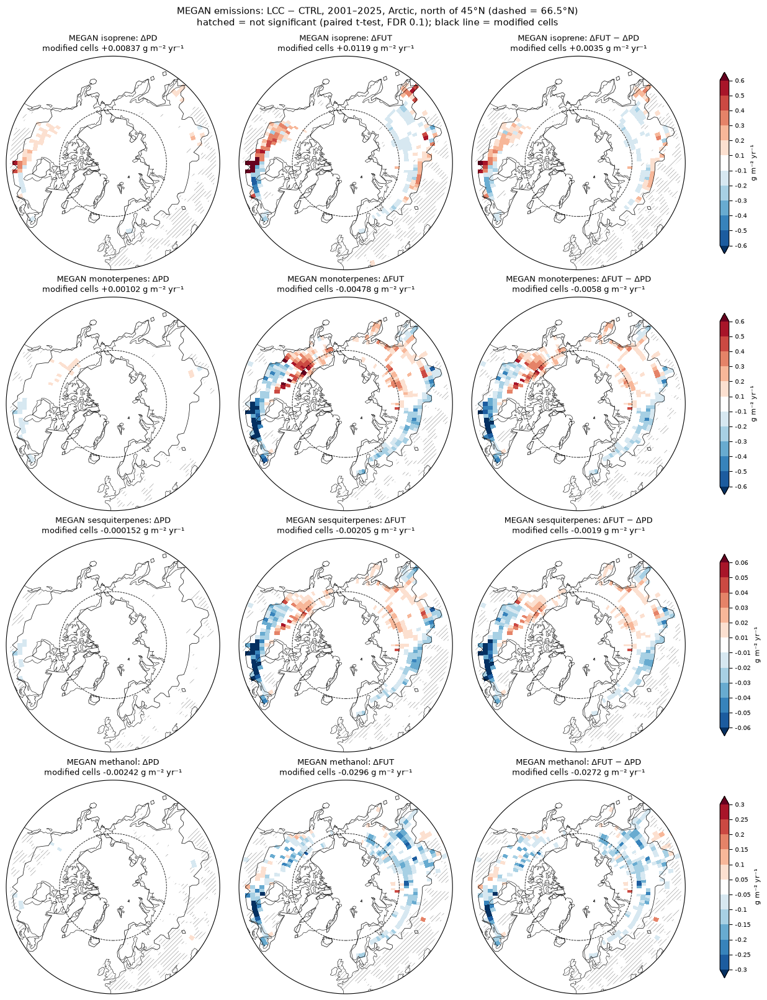

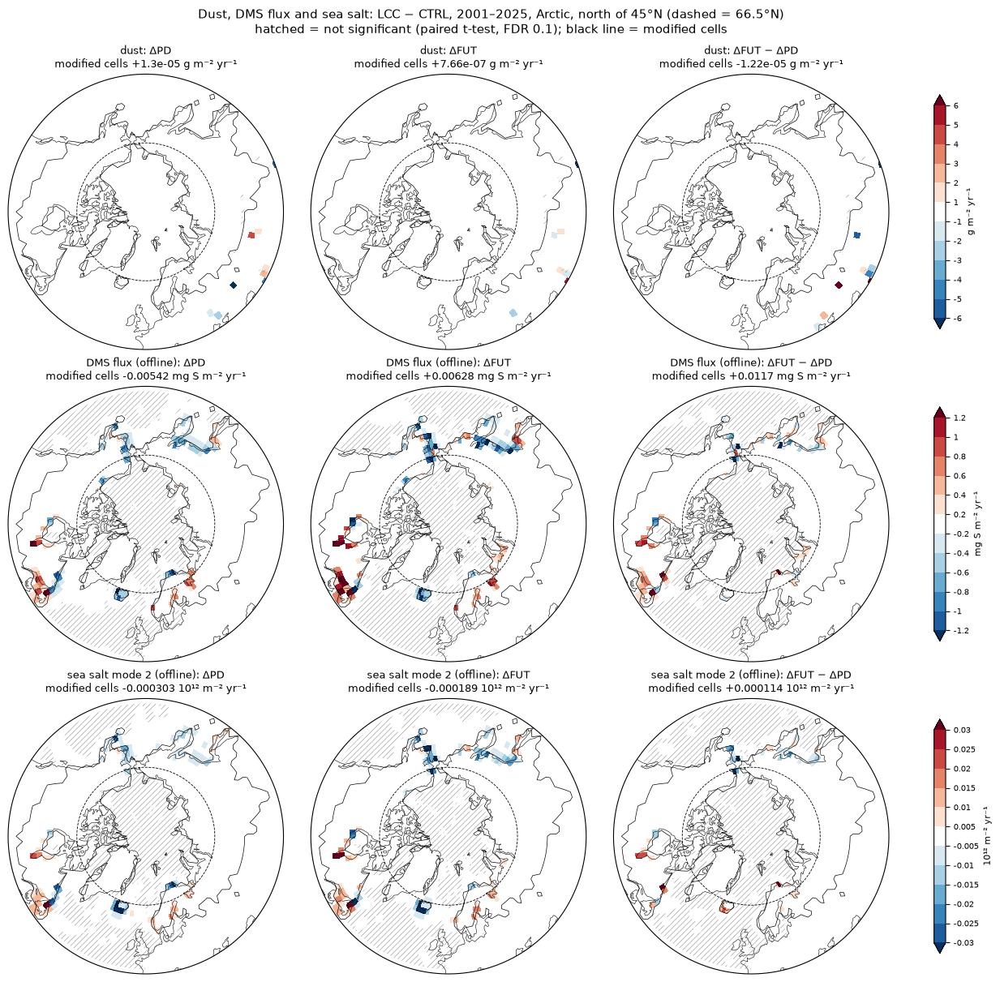

In [5]:
land = sum((SRC[k].ISOP.mean('year') > 0).astype(int) for k in CASES) > 0
dusty = sum((SRC[k].dust.mean('year') > 0).astype(int) for k in CASES) > 0
ocean = sum((SRC[k].open_ocean.mean('year') > 0).astype(int) for k in CASES) > 0
g = 1e3 * SEC_YR  # kg m-2 s-1 -> g m-2 yr-1
per_run = lambda f: {k: f(SRC[k]) for k in CASES}
contrast_maps([
    ('MEGAN isoprene', 'g m⁻² yr⁻¹', per_run(lambda d: d.ISOP * g), land),
    ('MEGAN monoterpenes', 'g m⁻² yr⁻¹', per_run(lambda d: d.MTERP * g), land),
    ('MEGAN sesquiterpenes', 'g m⁻² yr⁻¹', per_run(lambda d: d.BCARY * g), land),
    ('MEGAN methanol', 'g m⁻² yr⁻¹', per_run(lambda d: d.CH3OH * g), land),
], 'online_map_megan.png', 'MEGAN emissions')
contrast_maps([
    ('dust', 'g m⁻² yr⁻¹', per_run(lambda d: d.dust * g), dusty),
    ('DMS flux (offline)', 'mg S m⁻² yr⁻¹', per_run(lambda d: d.DMS_flux * g * 1e3 * MW_S / MW_DMS), ocean),
    ('sea salt mode 2 (offline)', '10¹² m⁻² yr⁻¹', per_run(lambda d: d.seasalt_n2 * SEC_YR * 1e-12), ocean),
], 'online_map_dust_dms_seasalt.png', 'Dust, DMS flux and sea salt')

### 2.1 Totals and time series of the online sources: global and north of 40°N

- **Levels:** stacked bars for the four runs, mean of 2001–2025 (error bar = ±1 s.d. of the yearly totals).
- **Effect:** ΔPD (navy) and ΔFUT (red) per component, with the 95 % CI of the paired yearly differences.
- **Time series:** yearly LCC − CTRL; **solid = ΔPD**, **dashed with dots = ΔFUT**; gold = sum of the components.

Lightning NOx is global only.

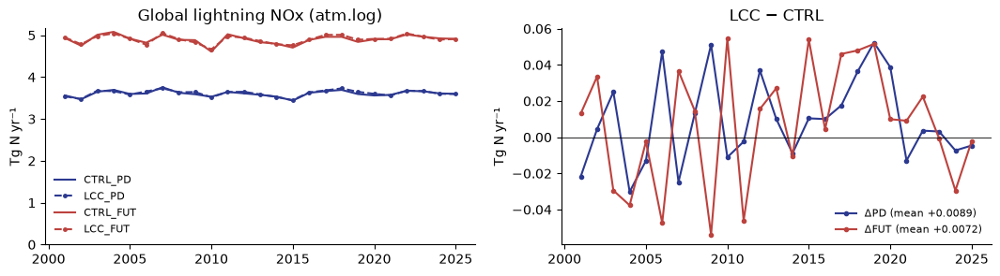

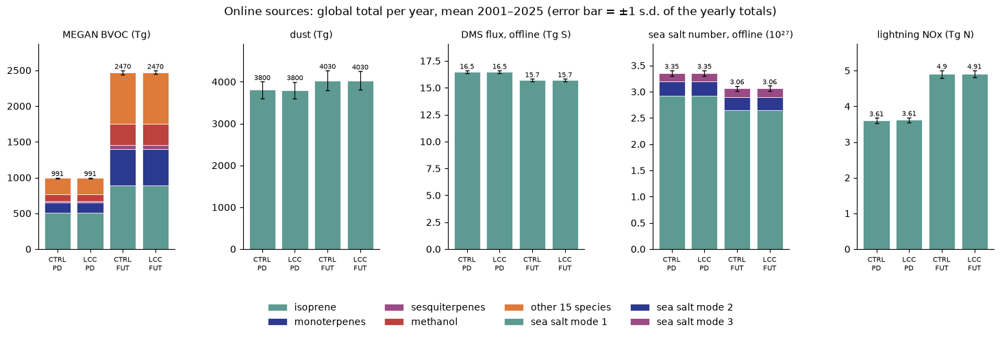

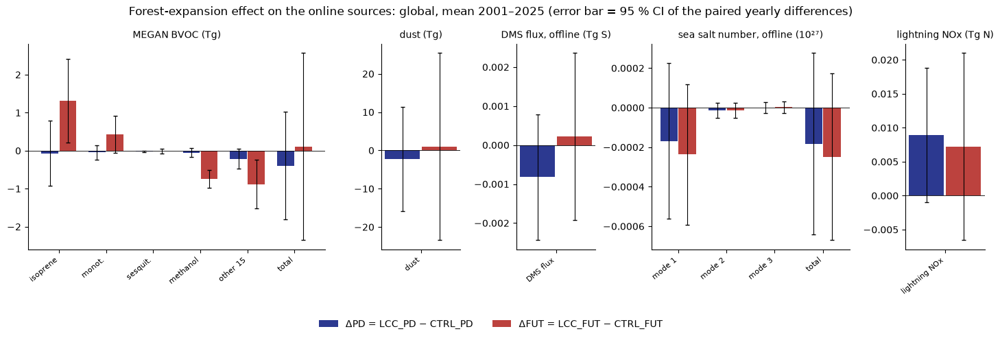

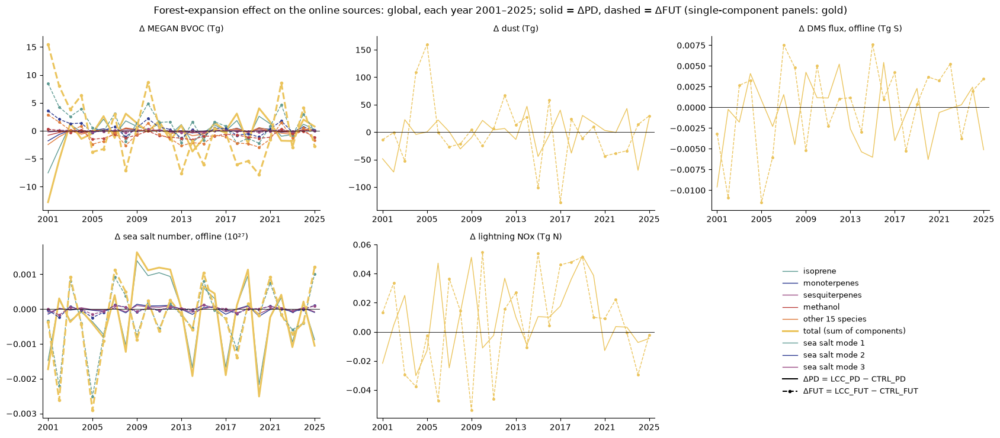

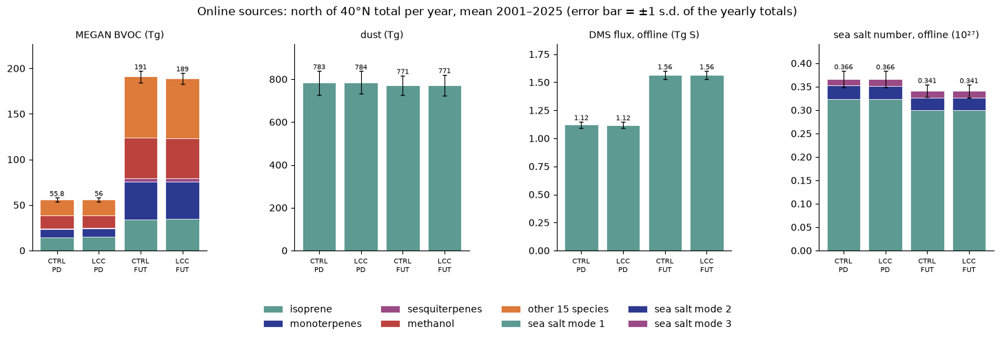

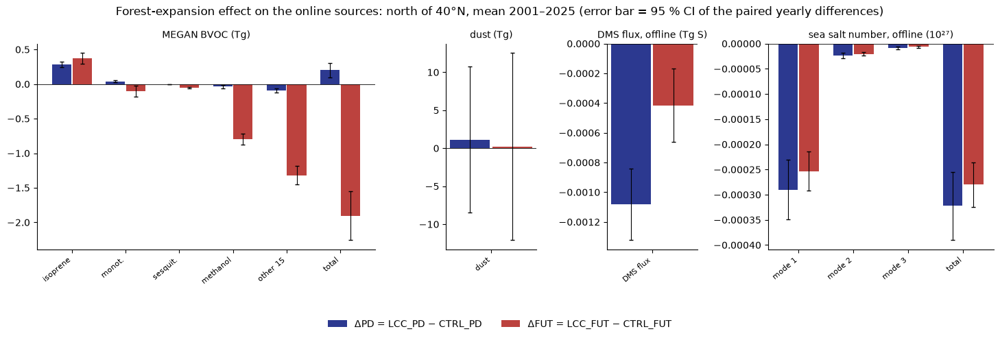

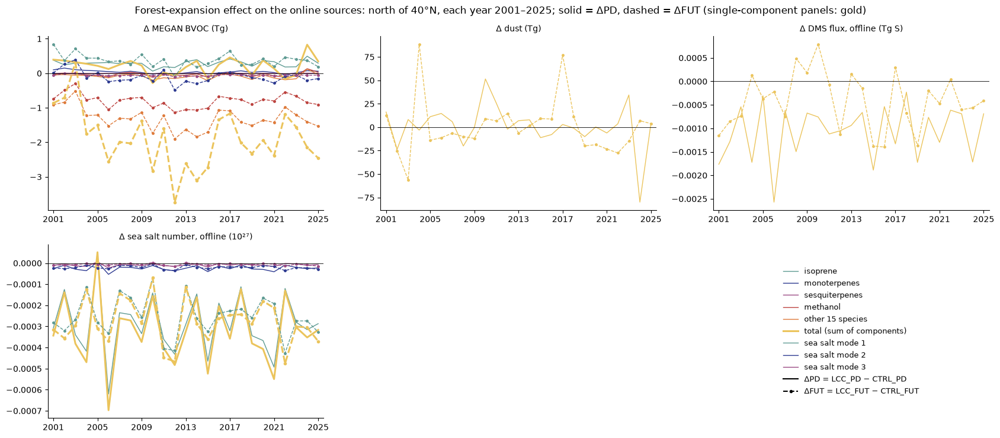

In [6]:
ONLINE = {  # panel -> {component: (function of SRC[run] -> kg or # m-2 s-1, factor to the panel unit)}
    'MEGAN BVOC (Tg)': {'isoprene': (lambda d: d.ISOP, 1e-9), 'monoterpenes': (lambda d: d.MTERP, 1e-9),
                        'sesquiterpenes': (lambda d: d.BCARY, 1e-9), 'methanol': (lambda d: d.CH3OH, 1e-9),
                        'other 15 species': (lambda d: sum(d[v] for v in MEG_OTHER), 1e-9)},
    'dust (Tg)': {'dust': (lambda d: d.dust, 1e-9)},
    'DMS flux, offline (Tg S)': {'DMS flux': (lambda d: d.DMS_flux * MW_S / MW_DMS, 1e-9)},
    'sea salt number, offline (10²⁷)': {f'sea salt mode {n}': (lambda d, n=n: d[f'seasalt_n{n}'], 1e-27) for n in (1, 2, 3)},
}
def online_totals(w):
    return {(k, panel): pd.DataFrame({c: (fn(SRC[k]) * w).sum(('lat', 'lon')).to_series() * SEC_YR * fac
                                      for c, (fn, fac) in comps.items()})
            for k in CASES for panel, comps in ONLINE.items()}
ONL = online_totals(AREA)
ONL_N = online_totals(AREA.where(AREA.lat >= LAT_BOX, 0))
for k in CASES:
    ONL[k, 'lightning NOx (Tg N)'] = pd.DataFrame({'lightning NOx': LIGHT[k]})
PANELS, PANELS_N = list(ONLINE) + ['lightning NOx (Tg N)'], list(ONLINE)
COMPCOL = dict(zip(['isoprene', 'monoterpenes', 'sesquiterpenes', 'methanol', 'other 15 species'], [TEAL, NAVY, PLUM, RED, ORANGE]))
COMPCOL.update({'sea salt mode 1': TEAL, 'sea salt mode 2': NAVY, 'sea salt mode 3': PLUM, 'dust': TEAL, 'DMS flux': TEAL, 'lightning NOx': TEAL})
assert all(list(ONL[k, p].index) == YEARS for k in CASES for p in PANELS)
pd.concat({f'{k}|{p}': ONL[k, p] for k in CASES for p in PANELS}, names=['run|panel', 'year']).to_csv(TAB / f'online_sources_global_yearly_{PROC_YEARS}.csv')
pd.concat({f'{k}|{p}': ONL_N[k, p] for k in CASES for p in PANELS_N}, names=['run|panel', 'year']).to_csv(TAB / f'online_sources_north{LAT_BOX}N_yearly_{PROC_YEARS}.csv')
assert np.isclose(ONL['LCC_PD', 'MEGAN BVOC (Tg)'].isoprene.mean(), SRC_TAB.loc[('MEGAN isoprene', 'Tg yr⁻¹', 'global'), 'LCC_PD'], rtol=1e-6)
assert np.isclose(ONL['LCC_FUT', 'dust (Tg)'].dust.mean(), SRC_TAB.loc[('dust', 'Tg yr⁻¹', 'global'), 'LCC_FUT'], rtol=1e-6)

def online_bars(ONL, PANELS, where, fname):
    fig, axs = plt.subplots(1, len(PANELS), figsize=(18, 3.9), gridspec_kw=dict(wspace=0.5))
    for ax, panel in zip(axs, PANELS):
        bottom = np.zeros(4)
        for c in ONL['CTRL_PD', panel].columns:
            v = np.array([ONL[k, panel][c].mean() for k in CASES])
            ax.bar(range(4), v, bottom=bottom, color=COMPCOL[c], edgecolor='white', lw=0.5, label=c)
            bottom += v
        sd = [ONL[k, panel].sum(axis=1).std(ddof=1) for k in CASES]
        ax.errorbar(range(4), bottom, yerr=sd, fmt='none', ecolor='k', elinewidth=0.8, capsize=2.5)
        for x, (v, e) in enumerate(zip(bottom, sd)):
            ax.text(x, v + e, f'{float(f"{v:.3g}"):g}', ha='center', va='bottom', fontsize=7)
        ax.set_xticks(range(4), [k.replace('_', '\n') for k in CASES], fontsize=7.5)
        ax.set_title(panel, fontsize=10); ax.set_ylim(0, (bottom + sd).max() * 1.15)
        ax.spines[['top', 'right']].set_visible(False)
    h, l = [], []
    for ax in axs:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l and ll not in ('dust', 'DMS flux', 'lightning NOx'):
                h.append(hh); l.append(ll)
    fig.legend(h, l, loc='upper center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle(f'Online sources: {where} total per year, mean {YRS} (error bar = ±1 s.d. of the yearly totals)', y=1.02)
    fig.savefig(FIG / fname, dpi=200, bbox_inches='tight'); plt.show()

def delta(ONL, b, panel):
    c, l = PAIRS[b]
    return ONL[l, panel] - ONL[c, panel]

def effect_bars(ONL, PANELS, where, fname):
    fig, axs = plt.subplots(1, len(PANELS), figsize=(18, 3.9), gridspec_kw=dict(wspace=0.38, width_ratios=[max(ONL['CTRL_PD', p].shape[1] + (ONL['CTRL_PD', p].shape[1] > 1), 1.6) for p in PANELS]))
    for ax, panel in zip(axs, PANELS):
        comps = list(ONL['CTRL_PD', panel].columns)
        labels = comps + (['total'] if len(comps) > 1 else [])
        for j, b in enumerate(PAIRS):
            d = delta(ONL, b, panel)
            if len(comps) > 1:
                d = d.assign(total=d.sum(axis=1))
            s = [mean_ci_p(d[c].values) for c in labels]
            ax.bar(np.arange(len(labels)) + (j - 0.5) * 0.38, [x[0] for x in s], 0.36, yerr=[x[1] for x in s], color=PCOL[b],
                   error_kw=dict(elinewidth=0.8, capsize=2), label=f'Δ{b} = LCC_{b} − CTRL_{b}')
        ax.axhline(0, color='k', lw=0.6)
        ax.set_xticks(range(len(labels)), [x.replace(' species', '').replace('sea salt ', '').replace('sesquiterpenes', 'sesquit.').replace('monoterpenes', 'monot.') for x in labels], rotation=40, ha='right', fontsize=8)
        ax.set_title(panel, fontsize=10); ax.spines[['top', 'right']].set_visible(False)
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle(f'Forest-expansion effect on the online sources: {where}, mean {YRS} (error bar = 95 % CI of the paired yearly differences)', y=1.02)
    fig.savefig(FIG / fname, dpi=200, bbox_inches='tight'); plt.show()

def effect_series(ONL, PANELS, where, fname):
    fig, axs = plt.subplots(2, 3, figsize=(17, 7.5))
    for ax in axs.flat[len(PANELS):-1]:
        ax.axis('off')
    for ax, panel in zip(axs.flat, PANELS):
        for b, ls, mk in [('PD', '-', None), ('FUT', '--', 'o')]:
            s = delta(ONL, b, panel)
            multi = s.shape[1] > 1
            for c in s.columns:
                ax.plot(s.index, s[c].values, ls=ls, marker=mk, ms=2.5, lw=1, color=COMPCOL[c] if multi else GOLD,
                        label=(c if multi else 'total') if b == 'PD' else None)
            if multi:
                ax.plot(s.index, s.sum(axis=1).values, ls=ls, marker=mk, ms=3, lw=2.2, color=GOLD, label='total (sum of components)' if b == 'PD' else None)
        ax.axhline(0, color='k', lw=0.6); ax.set_title('Δ ' + panel, fontsize=10)
        ax.set_xlim(YEARS[0] - 0.5, YEARS[-1] + 0.5); ax.set_xticks(range(2001, 2026, 4))
        ax.spines[['top', 'right']].set_visible(False)
    h, l = [], []
    for ax in axs.flat[:len(PANELS)]:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l and ll != 'total':
                h.append(hh); l.append(ll)
    h += [plt.Line2D([], [], color='k', ls='-'), plt.Line2D([], [], color='k', ls='--', marker='o', ms=3)]
    l += ['ΔPD = LCC_PD − CTRL_PD', 'ΔFUT = LCC_FUT − CTRL_FUT']
    axs.flat[-1].axis('off'); axs.flat[-1].legend(h, l, loc='center', frameon=False, fontsize=9)
    fig.suptitle(f'Forest-expansion effect on the online sources: {where}, each year {YRS}; solid = ΔPD, dashed = ΔFUT (single-component panels: gold)')
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=200, bbox_inches='tight'); plt.show()

# lightning NOx: levels and effect per year
fig, axs = plt.subplots(1, 2, figsize=(13, 3))
for b, (c, l) in PAIRS.items():
    axs[0].plot(LIGHT[c].index, LIGHT[c].values, '-', color=PCOL[b], label=c)
    axs[0].plot(LIGHT[l].index, LIGHT[l].values, '--o', ms=2.5, color=PCOL[b], label=l)
    d = LIGHT[l] - LIGHT[c]
    axs[1].plot(d.index, d.values, 'o-', ms=3, color=PCOL[b], label=f'Δ{b} (mean {d.mean():+.4f})')
axs[0].set_ylim(bottom=0); axs[0].set_ylabel('Tg N yr⁻¹'); axs[0].set_title('Global lightning NOx (atm.log)')
axs[1].axhline(0, color='k', lw=0.6); axs[1].set_ylabel('Tg N yr⁻¹'); axs[1].set_title('LCC − CTRL')
for ax in axs:
    ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False)
fig.savefig(FIG / 'lightning_nox_yearly.png', dpi=200, bbox_inches='tight'); plt.show()

online_bars(ONL, PANELS, 'global', 'online_totals_mean.png')
effect_bars(ONL, PANELS, 'global', 'online_effect_mean.png')
effect_series(ONL, PANELS, 'global', 'online_effect_timeseries.png')
online_bars(ONL_N, PANELS_N, f'north of {LAT_BOX}°N', f'online_totals_mean_north{LAT_BOX}N.png')
effect_bars(ONL_N, PANELS_N, f'north of {LAT_BOX}°N', f'online_effect_mean_north{LAT_BOX}N.png')
effect_series(ONL_N, PANELS_N, f'north of {LAT_BOX}°N', f'online_effect_timeseries_north{LAT_BOX}N.png')

## 3. What the model makes of it

The union of the variables in the two source notebooks: AOD, absorption AOD, SOA and sulfate burdens, droplet column, surface isoprene, monoterpenes, OH, SO₂, DMS, NOx, O₃, CO, CH₄, and the O₃ column. Processed monthly files, yearly means weighted by days per month; surface = lowest model level. SOA burden = `cb_SOA_A1 + cb_SOA_NA + cb_SOA_A1_OCW + cb_SOA_NA_OCW` (interstitial + cloud-borne). Surface CH₄ is set by the boundary condition, so it is in the table but has no map.

In [7]:
MODEL_VARS = {  # name: (category, variable(s), surface?, factor, unit)
    'AOD 550 nm': ('AEROPT', ['DOD550'], False, 1, '1'),
    'absorption AOD 550 nm': ('AEROPT', ['ABS550'], False, 1, '1'),
    'SOA burden': ('SOA', ['cb_SOA_A1', 'cb_SOA_NA', 'cb_SOA_A1_OCW', 'cb_SOA_NA_OCW'], False, 1e6, 'mg m⁻²'),
    'sulfate burden': ('SULFATE', ['cb_SULFATE'], False, 1e6, 'mg m⁻²'),
    'droplet column': ('CLOUDPROP', ['CDNUMC'], False, 1e-10, '10¹⁰ m⁻²'),
    'surface isoprene': ('BVOC', ['ISOP'], True, 1e12, 'ppt'),
    'surface monoterpenes': ('BVOC', ['MTERP'], True, 1e12, 'ppt'),
    'surface OH': ('CHEM', ['OH'], True, 1e15, 'ppq'),
    'surface SO₂': ('SULFATE', ['SO2'], True, 1e12, 'ppt'),
    'surface DMS': ('SULFATE', ['DMS'], True, 1e12, 'ppt'),
    'surface NOx': ('CHEM', ['NO', 'NO2'], True, 1e12, 'ppt'),
    'surface O₃': ('CHEM', ['O3'], True, 1e9, 'ppb'),
    'surface CO': ('CHEM', ['CO'], True, 1e9, 'ppb'),
    'surface CH₄': ('CHEM', ['CH4'], True, 1e9, 'ppb'),
    'O₃ column': ('CHEM', ['cb_O3'], False, 1e3, 'g m⁻²'),
}

def load_model(k):
    out, files = {}, {}
    for name, (cat, vs, sfc, fac, unit) in MODEL_VARS.items():
        f = PROC / f'{k}_atm_{cat}_{PROC_YEARS}.nc'
        if f not in files:
            files[f] = xr.open_dataset(f)
            assert files[f].attrs['casename'] == CASES[k], (f, files[f].attrs['casename'])
            assert files[f].time.encoding.get('calendar') == 'noleap'
        ds = files[f]
        if sfc:
            assert float(ds.lev[-1]) > 900
        da = sum(ds[v].isel(lev=-1) if sfc else ds[v] for v in vs)
        assert np.allclose(da.lat, AREA.lat) and np.allclose(da.lon, AREA.lon)
        out[name] = (yearly(da, YEARS) * fac).assign_coords(lat=AREA.lat, lon=AREA.lon).load()
    for ds in files.values():
        ds.close()
    return out

MODEL = {k: load_model(k) for k in CASES}
MODEL_TAB = region_table({n: (MODEL_VARS[n][4], {k: MODEL[k][n] for k in CASES}, 1, 'mean') for n in MODEL_VARS},
                         f'model_levels_lcc_ctrl_pd_fut_{PROC_YEARS}.csv')
show(MODEL_TAB)

global


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
AOD 550 nm,1,0.203,-0.000137,-0.0675,0.343,0.216,-3.4e-05,-0.0158,0.911,0.000103,0.771
absorption AOD 550 nm,1,0.00483,-2.48e-06,-0.0513,0.505,0.0044,4.95e-07,0.0113,0.948,2.97e-06,0.731
SOA burden,mg m⁻²,2.45,-0.00282,-0.115,0.303,6.71,0.00253,0.0377,0.651,0.00535,0.438
sulfate burden,mg m⁻²,6.23,0.00526,0.0845,0.00667,3.78,0.00477,0.126,0.00331,-0.000489,0.84
droplet column,10¹⁰ m⁻²,1.16,-0.00157,-0.136,2.66e-05,1.05,-0.000651,-0.0621,0.0746,0.000916,0.0782
surface isoprene,ppt,693,-0.759,-0.11,0.225,1.67e+03,3.72,0.222,0.0677,4.47,0.0761
surface monoterpenes,ppt,103,-0.126,-0.122,0.113,532,0.922,0.173,0.0874,1.05,0.0811
surface OH,ppq,59.3,0.00197,0.00332,0.834,48.3,0.00551,0.0114,0.548,0.00354,0.77
surface SO₂,ppt,297,0.248,0.0835,2.17e-08,96.9,0.022,0.0227,0.303,-0.226,2.5e-05


modified cells


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
AOD 550 nm,1,0.107,-0.000445,-0.414,0.0858,0.0876,-0.000101,-0.115,0.581,0.000344,0.281
absorption AOD 550 nm,1,0.00306,-8.9e-06,-0.291,0.156,0.00239,8.83e-07,0.0369,0.828,9.78e-06,0.195
SOA burden,mg m⁻²,1.31,0.00362,0.276,0.217,4.07,0.00921,0.226,0.0884,0.00559,0.334
sulfate burden,mg m⁻²,8.67,0.00263,0.0303,0.544,4.74,0.00423,0.0893,0.237,0.00161,0.799
droplet column,10¹⁰ m⁻²,1.77,-0.0115,-0.65,1.4e-09,1.54,-0.0115,-0.746,9.1e-15,3.83e-05,0.98
surface isoprene,ppt,50.7,3.69,7.27,2.76e-18,235,5.01,2.13,7.34e-10,1.32,0.00673
surface monoterpenes,ppt,29.7,0.363,1.22,2.44e-09,194,-2.82,-1.45,6.64e-10,-3.18,7.59e-12
surface OH,ppq,23.5,-0.152,-0.645,4.03e-13,15.7,0.0762,0.486,5.08e-13,0.228,9.96e-17
surface SO₂,ppt,482,2.28,0.474,3.97e-12,73.7,0.573,0.777,8.92e-10,-1.71,3.79e-09


46–82°N


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
AOD 550 nm,1,0.135,-0.000487,-0.362,0.0708,0.114,-0.000244,-0.215,0.265,0.000243,0.476
absorption AOD 550 nm,1,0.00341,-9.55e-06,-0.28,0.144,0.00258,-2.26e-06,-0.0876,0.633,7.29e-06,0.352
SOA burden,mg m⁻²,1.32,0.000376,0.0285,0.895,3.95,-0.000688,-0.0174,0.896,-0.00106,0.854
sulfate burden,mg m⁻²,8.91,0.00424,0.0476,0.304,4.79,0.00499,0.104,0.156,0.000749,0.902
droplet column,10¹⁰ m⁻²,1.84,-0.00707,-0.384,2.26e-09,1.58,-0.00583,-0.368,1.7e-12,0.00123,0.235
surface isoprene,ppt,36.5,1.74,4.76,1.57e-17,151,2.45,1.62,1.97e-10,0.713,0.00218
surface monoterpenes,ppt,18,0.168,0.929,1.76e-07,113,-1.21,-1.07,4e-09,-1.38,2.88e-11
surface OH,ppq,28.7,-0.0539,-0.188,3.59e-06,23.4,0.0477,0.204,4.64e-09,0.102,2.73e-09
surface SO₂,ppt,526,1.35,0.257,1.11e-11,82.2,0.267,0.325,4.54e-10,-1.08,5.11e-10


Arctic >66.5°N


,,CTRL_PD,ΔPD,ΔPD %,ΔPD p,CTRL_FUT,ΔFUT,ΔFUT %,ΔFUT p,ΔFUT − ΔPD,ΔFUT − ΔPD p
variable,unit,,,,,,,,,,
AOD 550 nm,1,0.0781,-0.000365,-0.467,0.0213,0.0649,-7.46e-05,-0.115,0.501,0.00029,0.146
absorption AOD 550 nm,1,0.00218,-7.83e-06,-0.359,0.0398,0.00142,2.03e-08,0.00143,0.993,7.85e-06,0.0722
SOA burden,mg m⁻²,1.05,0.00136,0.13,0.645,3.04,0.0164,0.54,0.00772,0.015,0.0193
sulfate burden,mg m⁻²,7.89,0.000111,0.00141,0.98,4.69,0.00248,0.053,0.513,0.00237,0.72
droplet column,10¹⁰ m⁻²,1.24,0.00591,0.478,2.99e-09,1.54,0.00687,0.446,3.24e-10,0.000956,0.327
surface isoprene,ppt,6.92,0.462,6.68,3.3e-08,43.7,-1.89,-4.33,1.25e-08,-2.36,1.22e-10
surface monoterpenes,ppt,2.67,0.795,29.8,2.76e-24,19.1,4.09,21.4,1.66e-24,3.29,5.71e-24
surface OH,ppq,14.5,-0.142,-0.978,6.44e-18,10.8,-0.0476,-0.439,6.19e-08,0.0943,2.53e-11
surface SO₂,ppt,166,0.795,0.48,1.19e-08,41.8,0.152,0.363,0.00801,-0.643,3.72e-06


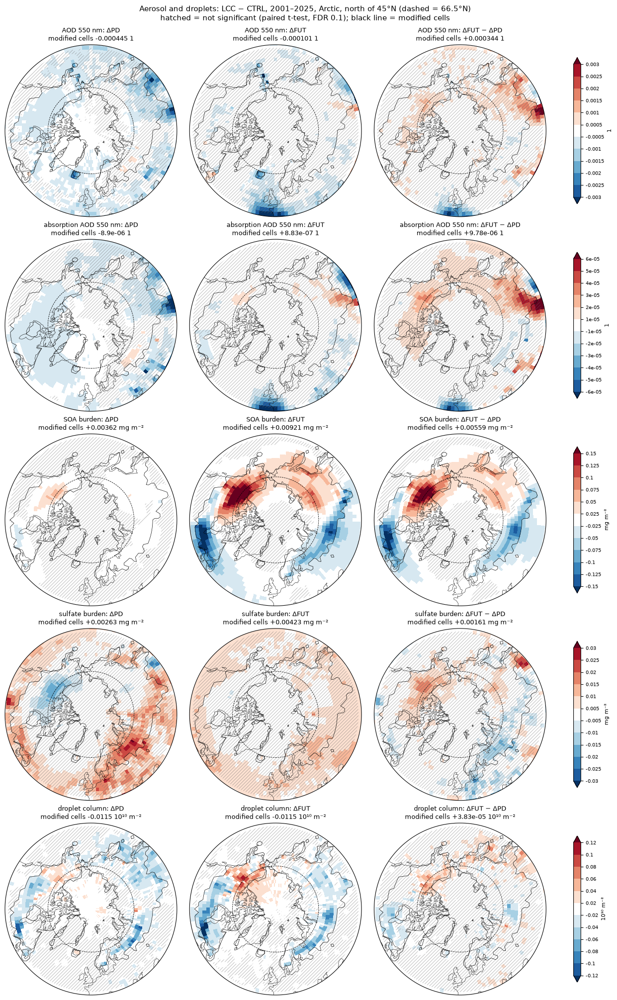

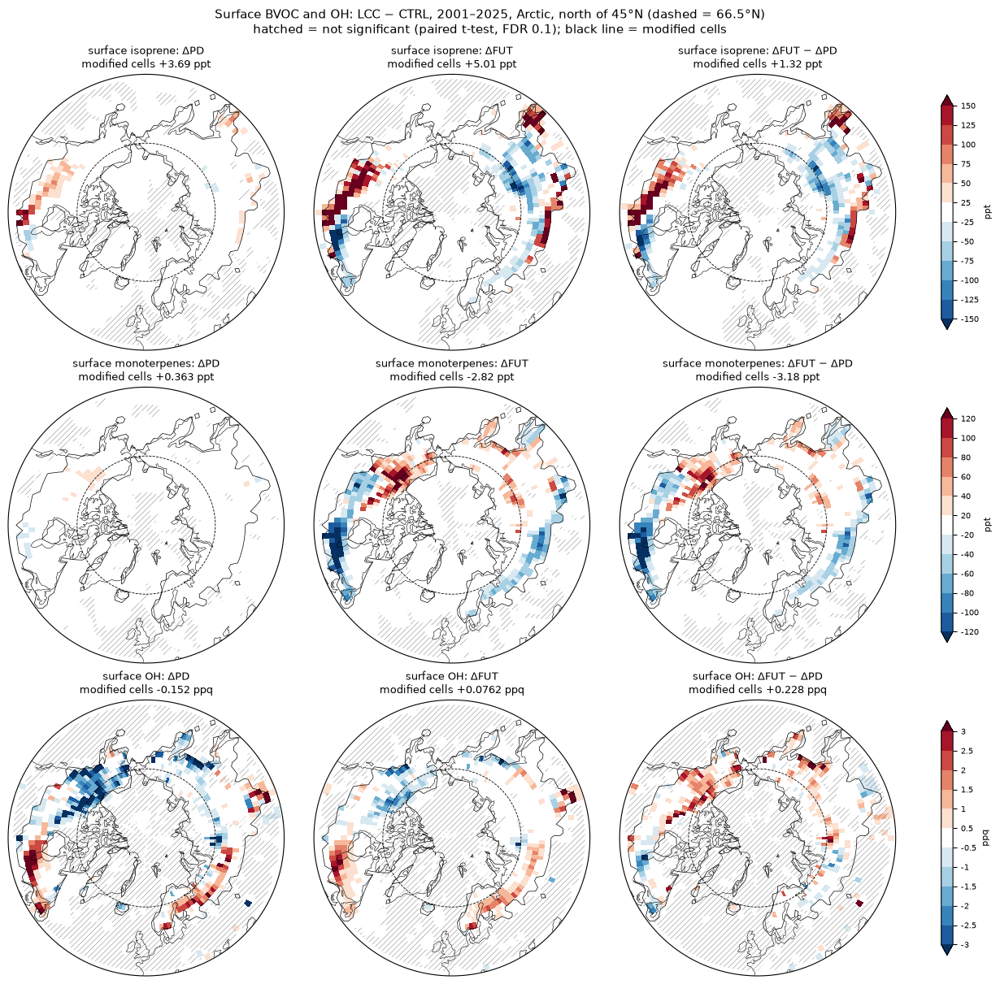

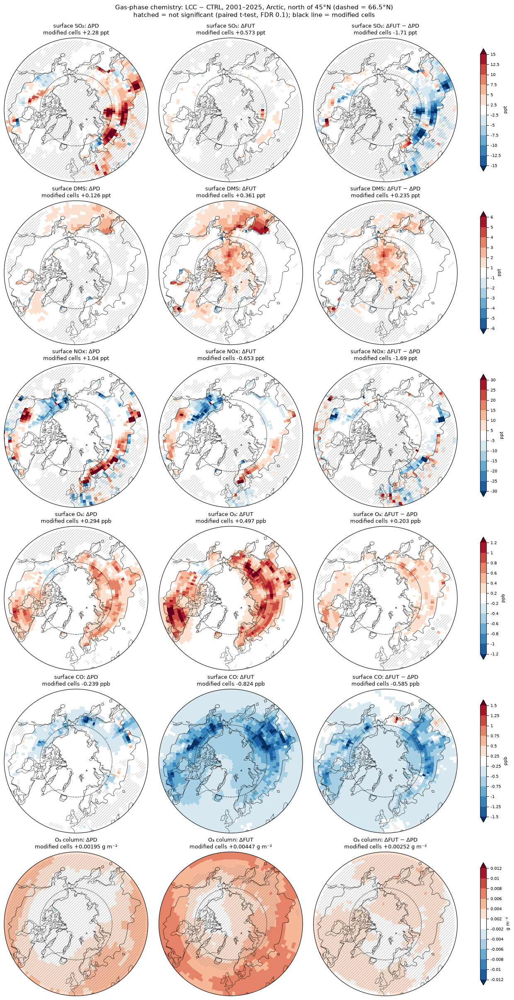

In [8]:
allc = AREA > 0
model_rows = lambda names: [(n, MODEL_VARS[n][4], {k: MODEL[k][n] for k in CASES}, allc) for n in names]
contrast_maps(model_rows(['AOD 550 nm', 'absorption AOD 550 nm', 'SOA burden', 'sulfate burden', 'droplet column']),
              'model_map_aerosol_cloud.png', 'Aerosol and droplets')
contrast_maps(model_rows(['surface isoprene', 'surface monoterpenes', 'surface OH']), 'model_map_bvoc_oh.png', 'Surface BVOC and OH')
contrast_maps(model_rows(['surface SO₂', 'surface DMS', 'surface NOx', 'surface O₃', 'surface CO', 'O₃ column']),
              'model_map_chemistry.png', 'Gas-phase chemistry')

### 3.1 Far-field check: tropical isoprene

The land cover differs only at 46–82°N, yet the global maps show LCC − CTRL isoprene differences in the Amazon and Congo. This cell tests whether they are a persistent response or internal variability plus a start-up transient: tropical (30°S–30°N) MEGAN isoprene by period, the gross cell-by-cell difference, the correlation between the difference patterns of two independent decades, and the share of tropical land cells with uncorrected p < 0.05 (5 % expected by chance).

In [2]:
def yearly_mean(da):
    w = da.time.dt.days_in_month
    return (da * w).groupby('time.year').sum('time') / w.groupby('time.year').sum('time')

ISO = {}
for k in CASES:
    with xr.open_dataset(PROC / f'{k}_atm_BVOC_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == CASES[k]
        ISO[k] = yearly_mean(ds.MEG_ISOP).assign_coords(lat=AREA.lat, lon=AREA.lon).load()
TROP, TG = (AREA.lat >= -30) & (AREA.lat <= 30), 1e-9 * 365 * 86400
rows = {}
for b, (c, l) in PAIRS.items():
    d = ISO[l] - ISO[c]
    land = ISO[c].mean('year') > 1e-13
    net = (d * AREA).where(TROP).sum(('lat', 'lon')) * TG
    gross = lambda x: float((abs(x) * AREA).where(TROP & land).sum()) * TG
    d1, d2 = d.sel(year=slice(2006, 2015)).mean('year'), d.sel(year=slice(2016, 2025)).mean('year')
    x = np.c_[d1.where(TROP & land).values.ravel(), d2.where(TROP & land).values.ravel()]
    x = x[np.isfinite(x).all(1)]
    pv = pvalue(d).where(TROP & land).values
    rows[f'Δ{b}'] = {'CTRL tropical isoprene (Tg/yr)': float((ISO[c].mean('year') * AREA).where(TROP).sum()) * TG,
                     'net Δ 2001–2025': float(net.mean()), 'net Δ 2001': float(net.sel(year=2001)),
                     'net Δ 2002–2005': float(net.sel(year=slice(2002, 2005)).mean()),
                     'net Δ 2006–2025': float(net.sel(year=slice(2006, 2025)).mean()),
                     'gross |Δ| of cell means, 2006–2015': gross(d1), 'gross |Δ| of cell means, 2016–2025': gross(d2),
                     'pattern r, 2006–15 vs 2016–25': np.corrcoef(x.T)[0, 1],
                     '% tropical land cells p < 0.05': 100 * np.mean(pv[np.isfinite(pv)] < 0.05)}
FAR = pd.DataFrame(rows)
FAR.to_csv(TAB / f'farfield_tropical_isoprene_{PROC_YEARS}.csv')
with pd.option_context('display.float_format', '{:.3g}'.format):
    display(FAR)

,ΔPD,ΔFUT
CTRL tropical isoprene (Tg/yr),471,816
net Δ 2001–2025,-0.334,0.958
net Δ 2001,-7.46,7.29
net Δ 2002–2005,-0.79,2.44
net Δ 2006–2025,0.113,0.346
"gross |Δ| of cell means, 2006–2015",2.44,4.79
"gross |Δ| of cell means, 2016–2025",2.26,4.93
"pattern r, 2006–15 vs 2016–25",0.251,-0.00365
% tropical land cells p < 0.05,11.3,12.2


## 4. Summary

LCC − CTRL, 2001–2025, paired yearly differences. Tags: **(a)** read from the tables above · **(b)** inference. n.s. = p ≥ 0.05. Table p-values are not corrected for the many variables and regions tested.

**Inputs (a).** Within each background, CTRL and LCC differ only in land cover (`fsurdat`), their own initial files, and CTRL_FUT's extra 30-min BVOC output tape (output only). Both backgrounds use the same two land-cover files. SST, sea ice, greenhouse gases, seawater DMS and prescribed emissions are identical within each pair.

**Online sources, modified cells** (a)

| | ΔPD | ΔFUT | Does the background matter? (ΔFUT − ΔPD) |
|---|---|---|---|
| MEGAN isoprene | **+6.0 %** (+0.24 Tg yr⁻¹) | **+2.8 %** (+0.35 Tg yr⁻¹) | larger in Tg, smaller in % (p < 10⁻⁴) |
| MEGAN monoterpenes | +0.65 % | **−0.63 %** | **sign flip** (p < 10⁻⁶) |
| MEGAN sesquiterpenes | −1.5 % | −2.9 % | stronger decrease in FUT |
| MEGAN methanol | −1.9 % | **−4.8 %** | stronger decrease in FUT |
| MEGAN other 15 species | −2.4 % | **−5.1 %** | stronger decrease in FUT |
| dust | n.s. | n.s. | n.s. |
| DMS flux (offline, wind only) | −0.27 % | +0.19 % | very small |
| sea salt (offline, wind only) | −1.0 to −1.3 % | −0.2 to −0.5 % | very small |
| lightning NOx (global) | +0.25 % (n.s.) | +0.15 % (n.s.) | n.s. (p = 0.84) |

**What the model makes of it, modified cells** (a)

| | ΔPD | ΔFUT | ΔFUT − ΔPD |
|---|---|---|---|
| surface isoprene | +7.3 % | +2.1 % | p = 0.007 |
| surface monoterpenes | +1.2 % | −1.5 % | **sign flip** |
| surface OH | −0.65 % | +0.49 % | **sign flip** |
| surface NOx | +0.18 % | −0.24 % | **sign flip** |
| surface O₃ | +0.75 % (+0.29 ppb) | +1.30 % (+0.50 ppb) | larger in FUT |
| surface CO | −0.24 % | −0.76 % | larger in FUT |
| droplet column | −0.65 % | −0.75 % | **no difference** (p = 0.98) |
| SOA burden | +0.28 % (n.s.) | +0.23 % (n.s.) | n.s. |
| sulfate burden, AOD, absorption AOD | n.s. | n.s. | n.s. |

**Arctic >66.5°N** (a): monoterpene emissions rise in both backgrounds (+34 % PD, +28 % FUT, from a small base). The SOA burden rises only in FUT (+0.54 %, p < 0.05 for ΔFUT; ΔFUT − ΔPD p = 0.02, uncorrected).

**Tropical differences (§3.1)** (a): tropical isoprene differs although the land cover does not change there. The net difference is largest in 2001 (−7.5 Tg in PD, +7.3 Tg in FUT) and small in 2006–2025 (+0.11 and +0.35 Tg yr⁻¹). The cell patterns do not persist from 2006–15 to 2016–25 (r = 0.25 in PD, 0.00 in FUT).

Inferences (b):
- **The forest expansion does not measurably change the aerosol background in either climate.** SOA, sulfate and AOD are not significant over the modified cells, in PD or FUT.
- **The background climate changes the BVOC mix.** Isoprene increases in both, but monoterpenes switch from a small increase to a small decrease, and the oxygenated and other species fall about twice as much in % in FUT. The cause (PFT mix, leaf area, temperature, CO₂) is not separated here; the MEGAN LMDI analysis addresses it.
- **The droplet-column decrease is the same in both backgrounds** although the aerosol background is very different. With no significant aerosol change, this points to a land-surface or meteorological effect rather than aerosol. Not tested here.
- **Oxidant responses depend on the background:** OH falls in PD and rises in FUT over the modified cells, consistent with the different NOx and BVOC regimes. Not attributed here.
- **Treat small global MEGAN differences with caution.** The tropical part looks like a start-up transient plus internal variability, so it should not be read as a forced far-field response. This includes the formally significant global isoprene ΔFUT (+0.15 %, p = 0.02). The regional results over the modified cells are the ones to use.

## Appendix: global maps

The same maps as in §2–3, over the whole globe (Robinson projection). Colour levels and FDR are recomputed from the global fields. Files in `figures/appendix-global/`.

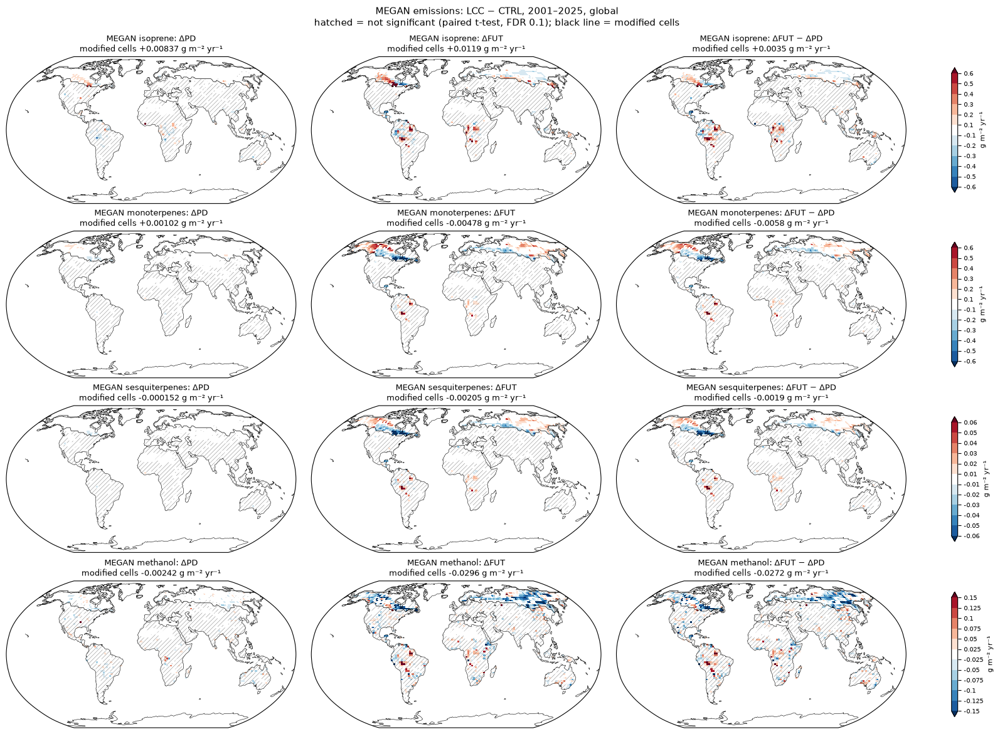

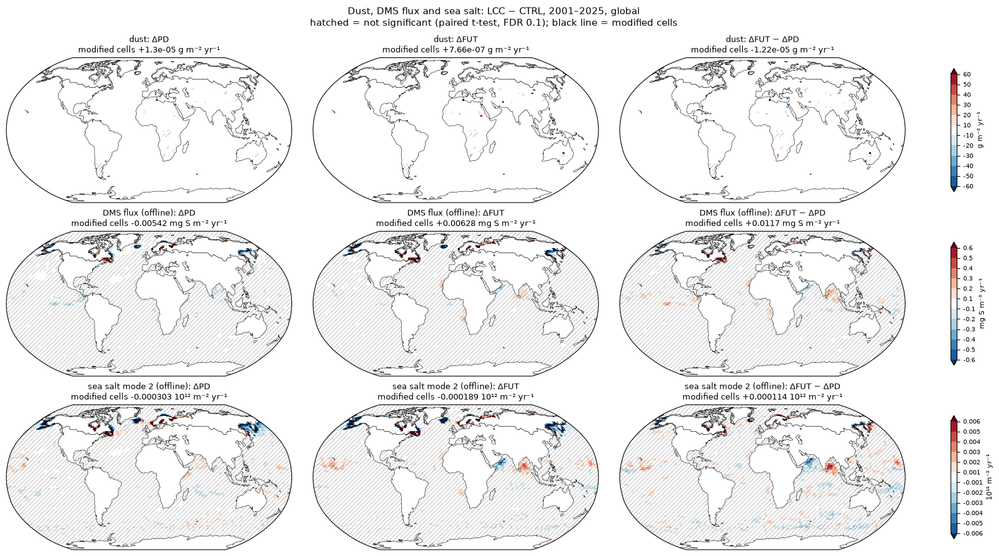

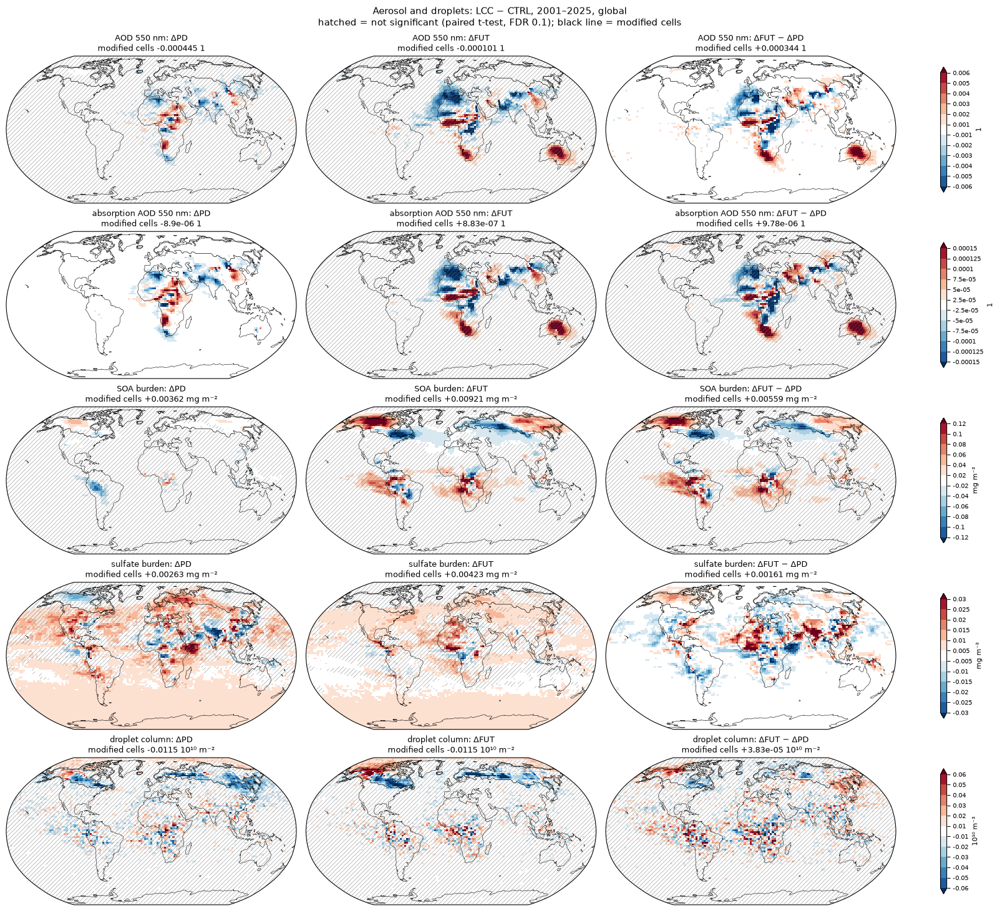

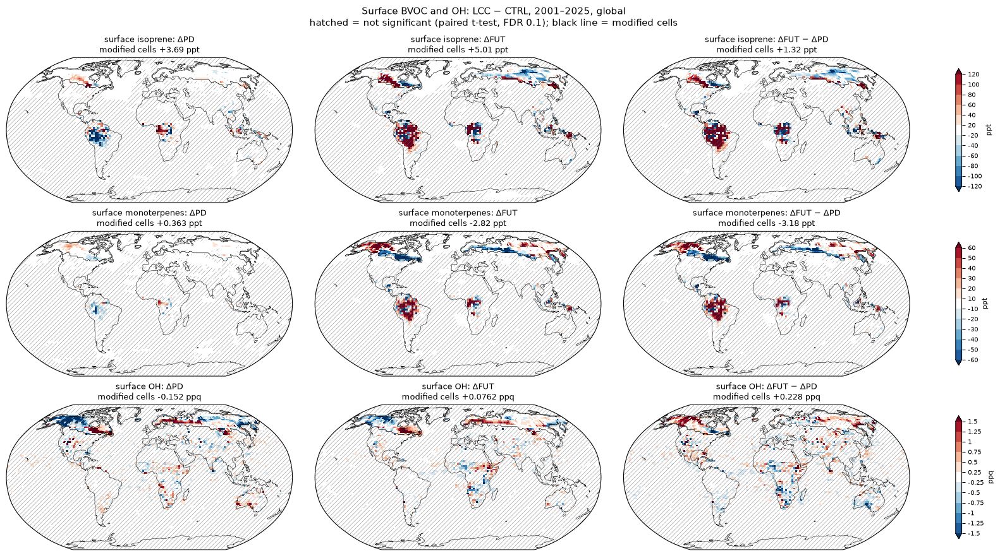

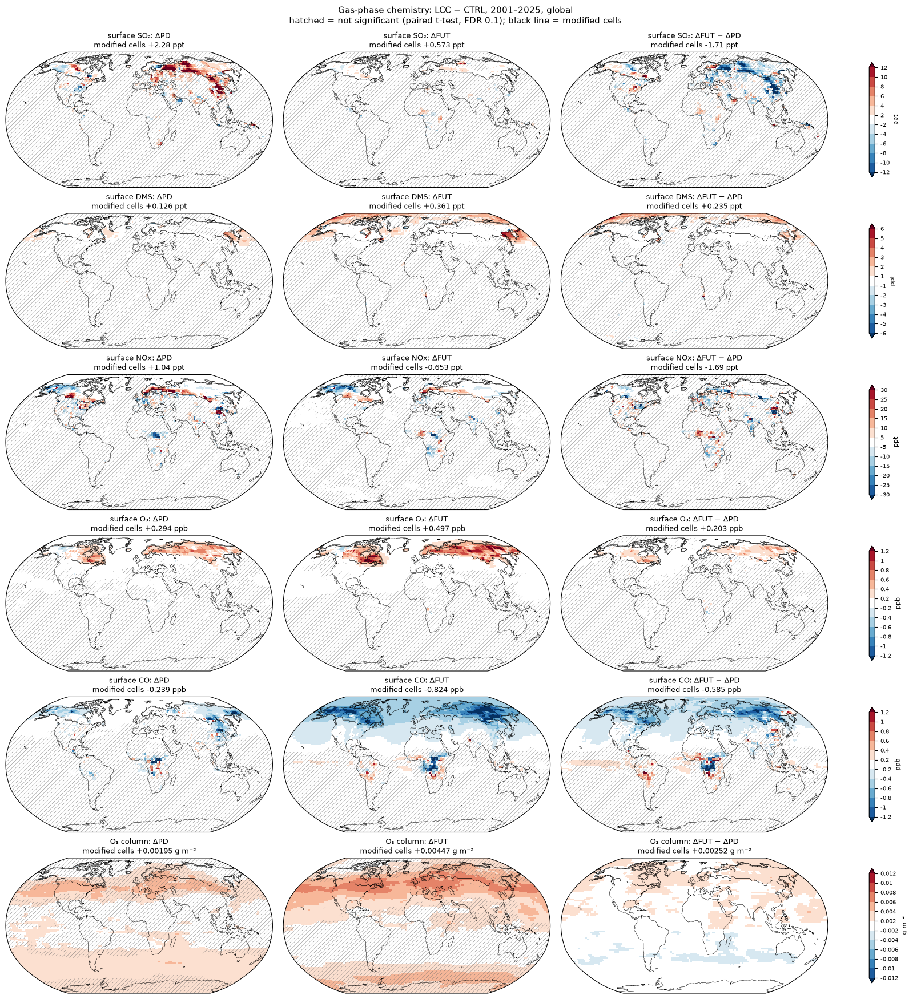

In [9]:
for fn, args, kw in list(APPENDIX):
    fn(*args, region='global', **kw)